# Figure 2 — ocean graph defects

One row, four panels:

| Inspect · map | distribution | ‖ | Inspect · map | distribution |
|---|---|---|---|---|
| mesh edges thresholded on **length** | edge-length histogram | | grid nodes thresholded on **degree** | node-degree lollipop |

Left block: long m2m edges stepping over land. Right block: grid nodes with no
encoder edge (`g2m`) or no decoder edge (`m2g`). A dotted rule separates them.

Everything that draws lives in [`figure2_builder.py`](figure2_builder.py). This
notebook is the content — the two block specs — plus the settings for one call.


## 1 · Setup

In [1]:
%load_ext autoreload
%autoreload 2

import figure2_builder as f2

# The figure is 5.5 in wide in POINTS, so the default renderer draws it as 396 CSS
# px — a postage stamp. Re-render at 3x for the screen; the export is untouched.
f2.use_png_renderer(scale=3)

f2.show_config(common=True)   # every name below is a keyword to f2.build()


27 of 106 settings
  ZOOM                    = 1.0
  FIG_W_IN                = 5.5
  MAP_H_IN                = 1.05
  MAP_W                   = 0.235
  DIST_W                  = 0.17
  GAP_MD                  = 0.046
  GAP_MID                 = 0.062
  MARGIN_IN               = {'l': 0.02, 'r': 0.03, 't': 0.17, 'b': 0.32}
  LEN_BINS                = 22
  CHART_LOG_Y             = True
  DIST_TITLE              = True
  SHOW_Y_TITLE            = False
  FLAG_COUNT_SCOPE        = 'crop'
  SHOW_LEGENDS            = True
  LEGEND_SCALE            = 1.0
  LEGEND_SUBGRAPH         = True
  DEGREE_BLOCK_EDGE_GREY  = True
  DEGREE_BLOCK_EDGE_ALPHA = 60
  EDGE_WIDTH_SCALE        = 0.42
  VIOL_NODE_BOOST         = 2.6
  NODE_SIZE_SCALE         = 1.0
  BASEMAP_ALPHA           = 0.55
  DIVIDER                 = True
  FONT_TITLE              = 6.5
  FONT_AXLAB              = 5.0
  FONT_TICK               = 4.6
  FONT_LEGEND             = 5.0


## 2 · Where the defects are

The crop catalogue, grouped by the failure mode each crop was found for. Any key
here goes in a block's `region=`.


In [2]:
f2.print_regions()

# The distribution a threshold has to be chosen against, before setting lo/hi:
# f2.metric_report("prod_cluster_default", "m2m_2", "length")
# f2.metric_report("prod_cluster_noconnect", "g2m", "grid_deg")



LENGTH    long mesh edges over land   ·  metric='length'   on m2m_*   [16]
   indonesia         (  -5.1,   125.0)  h= 22.0deg  densest land-crossing cluster: 12 edges at m2m_0, 7 at m2m_1, 4 at m2m_2
   java_flores       (  -6.1,   115.7)  h= 16.0deg  11 edges at m2m_0 -- Java Sea / Flores Sea straits
   solomon           (  -6.4,   152.9)  h= 16.0deg  8 edges at m2m_0; worst single edge 136 km / 61% over land
   philippines       (   6.7,   124.3)  h= 18.0deg  6 edges at m2m_0, 4 at m2m_1 -- Sulu / Celebes Sea
   svalbard          (  78.4,    14.7)  h=  9.0deg  the worst m2m_0 edge: 250 km, 70% over land, across Spitsbergen
   alaska_pen        (  56.0,  -160.0)  h= 14.0deg  5 edges at m2m_0; a 172 km edge 61% over the Alaska Peninsula
   japan             (  34.3,   133.1)  h= 13.0deg  m2m_1: a 327 km edge 70% over land, across Honshu
   baffin            (  63.8,   -68.3)  h= 16.0deg  m2m_1: a 439 km edge 61% over land, across Baffin Island
   scotland          (  58.0,    -3.8)  h

## 3 · Region × failure mode

The catalogue files each crop under the mode it was *found* for; this measures all
three in *every* crop, so a region that carries two shows up carrying two.
Takes ~20 s — it masks 675 k grid nodes per region.


In [3]:
f2.region_table()


region × failure mode   (panel aspect 1.272, crop heights from §3, ZOOM not applied)
  L  long m2m edges, undirected, on prod_cluster_default · m2m_0 ≥ 250 km · m2m_1 ≥ 400 km · m2m_2 ≥ 700 km
  G  grid nodes with no g2m edge, M  with no m2g edge, on prod_cluster_noconnect
  a letter needs ≥ 1 edge / ≥ 5 nodes in the crop

region            class       L0    L1    L2    g2m   m2g   modes
─────────────────────────────────────────────────────────────────
indonesia         length       1     2     3     38     3   L G ·
java_flores       length       0     0     0     13     1   · G ·
solomon           length       0     0     1      7     0   L G ·
philippines       length       0     0     2     34     9   L G M
svalbard          length       0     2     0     14     8   L G M
alaska_pen        length       2     0     0     12     5   L G M
japan             length       0     1     1     21     1   L G ·
baffin            length       3     2     3    114    13   L G M
scotland       

## 4 · The figure

`BLOCKS` is the content: one dict per panel. Everything else is a setting, passed
to `f2.build()` — the call below spells out the ones worth touching, and
`f2.show_config()` lists all 83. An unknown name raises rather than being ignored.


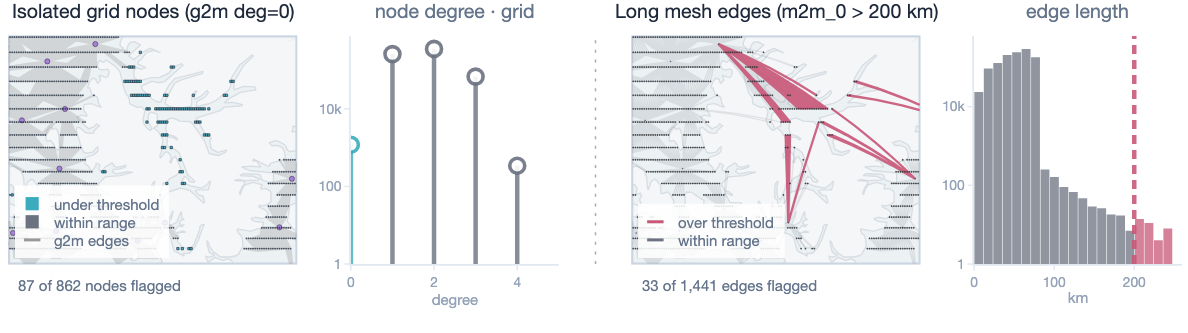

wrote /workspace/gnn-view/notebooks/figure2_ocean_defects_sequential.pdf
wrote /workspace/gnn-view/notebooks/figure2_ocean_defects_sequential.png
  5.5 x 1.540 in


[PosixPath('/workspace/gnn-view/notebooks/figure2_ocean_defects_sequential.pdf'),
 PosixPath('/workspace/gnn-view/notebooks/figure2_ocean_defects_sequential.png')]

In [7]:
# Each block carries its own `zoom=` and `legend_loc=`, so the two maps are
# magnified independently and each key goes in whichever corner that crop leaves
# empty. legend_loc takes "bottom-left" | "bottom-right" | "top-left" |
# "top-right" | "none"; the global defaults are ZOOM and LEGEND_LOC.

# ── which side of the grid↔mesh coupling the right-hand block interrogates ──
#   "g2m" -> deg_out == 0, grid nodes the encoder never reads from
#   "m2g" -> deg_in  == 0, grid nodes the decoder never writes back to
# metric="grid_deg" resolves to the correct side on its own, so this is the only
# edit needed to switch. On prod_cluster_noconnect: 1,183 nodes have no g2m edge,
# 179 no m2g edge, and only 128 have neither — they are different defects.
GRID_BLOCK = "g2m"

BLOCKS = [
    # Long mesh edges stepping over land. lo/hi are km; 700 flags 68 of 5,770
    # undirected m2m_2 edges graph-wide.
    dict(graph="prod_cluster_noconnect", subgraph="g2m", metric="grid_deg",
         lo=0, hi=None, region="canadian_arctic", zoom=2.0,
         legend_loc="bottom-left",
         title="Isolated grid nodes (g2m deg=0)"),

    # Grid nodes isolated from that subgraph. lo=0 isolates degree-0 exactly;
    # lo=1 would sweep in 257,667 legitimate degree-1 nodes. zoom=2 is not
    # cosmetic — at the catalogue height this crop holds ~10k g2m edges, which
    # fuse into bands rather than the texture the flagged nodes read against.
    #
    # show_subgraph=True draws the whole subgraph the degree was counted over --
    # semantic edge colour, mesh endpoints at full size, arrowheads once the crop
    # is small enough (<= SUBGRAPH_ARROW_MAX_E edges) -- instead of the greyed
    # context default. On m2g it reintroduces the cyan collision; see §7.
    dict(graph="prod_cluster_default", subgraph="g2m", metric="length",
         lo=None, hi=200, region="canadian_arctic", zoom=2.0,
         legend_loc="bottom-left",
         title="Long mesh edges (m2m_0 > 200 km)")
]

fig = f2.build(
    BLOCKS,

    # ── geometry ────────────────────────────────────────────────────────────
    ZOOM       = 1.0,     # multiplies every block's own zoom. >1 tightens the view
    FIG_W_IN   = 5.50,    # fixed by the column width
    MAP_H_IN   = 1.05,    # panel height for BOTH maps; with MAP_W this is the aspect
    MAP_W      = 0.235,   # map panel width, as a fraction of FIG_W_IN
    DIST_W     = 0.170,   # distribution panel width, same units
    GAP_MD     = 0.046,   # map -> its own distribution (must clear the y tick labels)
    GAP_MID    = 0.062,   # between the two blocks; the dotted rule sits in the middle
    MARGIN_IN  = dict(l=0.02, r=0.03, t=0.17, b=0.32),

    # ── what the panels show ────────────────────────────────────────────────
    FLAG_COUNT_SCOPE        = "crop",   # "crop" counts what the panel shows; "graph" counts globally
    LEN_BINS                = 22,       # edge-length histogram bins
    CHART_LOG_Y             = True,     # both distributions are heavy-tailed
    DIST_TITLE              = True,
    SHOW_Y_TITLE            = False,    # "count" costs more width than it explains at 5 pt
    SHOW_LEGENDS            = True,
    LEGEND_SUBGRAPH         = True,     # name the subgraph a degree was counted over
    DIVIDER                 = True,

    # ── marks ───────────────────────────────────────────────────────────────
    DEGREE_BLOCK_EDGE_GREY  = True,     # see the note in figure2_builder.py: colors.json
                                        #   gives m2g and "under threshold" the SAME cyan
    DEGREE_BLOCK_EDGE_ALPHA = 60,       # 0 drops a degree block's context edges entirely
    EDGE_WIDTH_SCALE        = 0.42,
    VIOL_NODE_BOOST         = 2.6,      # flagged nodes draw larger as well as darker
    NODE_SIZE_SCALE         = 1.0,

    # ── basemap ─────────────────────────────────────────────────────────────
    # plotly's layout.geo.resolution only accepts [110, 50]; there is no built-in
    # 10m. Measured on the arctic crop at zoom 3, plotly at 50 and Natural Earth at
    # 10m are visually equivalent, so 50 is enough and the PDF stays ~4x smaller.
    # "naturalearth" (with BASEMAP_NE_RES) draws the shapefiles through cartopy
    # instead -- worth it only if kaleido silently falls back to the 110m topojson,
    # which shows up as a blocky coastline with no error.
    BASEMAP_SOURCE          = "plotly",
    BASEMAP_ALPHA           = 0.55,

    # ── panel letters ───────────────────────────────────────────────────────
    # (a) (b) (c) … for a paper that cites panels in prose. Ordered the way a
    # reader scans: left to right across the row, and top to bottom inside a
    # split distribution column, so a dual block's two charts are consecutive.
    # They sit INSIDE the panel's top-left: the titles are centred and run the
    # full panel width, so placing them above collides ("(a)Mesh edges…").
    PANEL_LETTERS           = False,     # True to switch them on
    PANEL_LETTER_SCOPE      = "all",     # "maps" letters only the two maps
    PANEL_LETTER_FMT        = "({})",    # "{}" -> a   "{}." -> a.
    PANEL_LETTER_START      = "a",       # continue a multi-figure plate from, say, "c"

    # ── type ────────────────────────────────────────────────────────────────
    # Four roles, sized and coloured exactly as figure3_builder sizes and colours
    # its own, so the two figures set as one plate. FONT_S / FONT_XS are the two
    # base sizes every role defaults to — set either and the whole figure rescales;
    # naming a role in the same call overrides the fan-out for that role only.
    FONT_S     = 7.0,          # panel titles
    FONT_XS    = 6.0,          # everything else
    TITLE_FS   = 7.0,  TITLE_FC   = f2.TEXT,        # every panel title, map and chart
    LEGEND_FS  = 6.0,  LEGEND_FC  = f2.TEXT_MUTED,  # in-map key + the flagged-count line
    TICKNUM_FS = 6.0,  TICKNUM_FC = f2.TEXT_MUTED,  # numeric ticks, x and y
    AXLAB_FS   = 6.0,  AXLAB_FC   = f2.TEXT_MUTED,  # axis titles under those ticks

    # ── chart axis chrome ───────────────────────────────────────────────────
    # The distributions' own axes: figure3's soft black rather than the UI's slate
    # stroke, which all but vanishes at 0.5 pt on paper, plus its arrowheads.
    AXIS_COLOR = "rgba(0,0,0,0.333)",
    AXIS_WIDTH = 0.5,
    AXIS_ARROWS = True,

    # ── the key's card ──────────────────────────────────────────────────────
    LEGEND_BORDER    = "#e8ebee",   # a really light grey: bounds the card without
                                    #   being read as a mark of its own
    LEGEND_RADIUS_PX = 2.5,         # rounded corners
)

fig.show()

f2.export(fig, "figure2_ocean_defects_sequential", formats=("pdf", "png"), dpi=400)



## 6 · Two defects in one panel — the Baltic

Everywhere else the rule is one claim per panel. This crop is the exception: the
long `m2m_0` edges hopping Denmark and the low-degree mesh nodes they strand in the
Baltic are *the same finding*, and splitting them across two maps would destroy the
adjacency that makes the point.

So a block may carry a second claim: `metric="length"` thresholds the **edges** while
`node_metric="mesh_deg"` thresholds the **nodes**, with `node_lo` / `node_hi`. Both
are drawn in the one map, the key gets a row per claim, and the caption reports both
counts. `legend_labels` renames the key's rows, since "over threshold" twice would
be useless when the two claims mean different things.

The distribution column splits to match: **edge length on top, node degree
underneath**, one chart per claim, in the order the caption reports them. That is
automatic whenever a block sets `node_metric` — `DIST_SPLIT=False` turns it off,
`DIST_SPLIT_GAP` sets the space between the halves.


In [12]:
f2.configure(PANEL_LETTERS=True, PANEL_LETTER_SCOPE="all", PANEL_LETTER_FMT="({})", PANEL_LETTER_START="a",PANEL_LETTER_LOC="above")

{'PANEL_LETTERS': True,
 'PANEL_LETTER_SCOPE': 'all',
 'PANEL_LETTER_FMT': '({})',
 'PANEL_LETTER_START': 'a',
 'PANEL_LETTER_LOC': 'inside'}

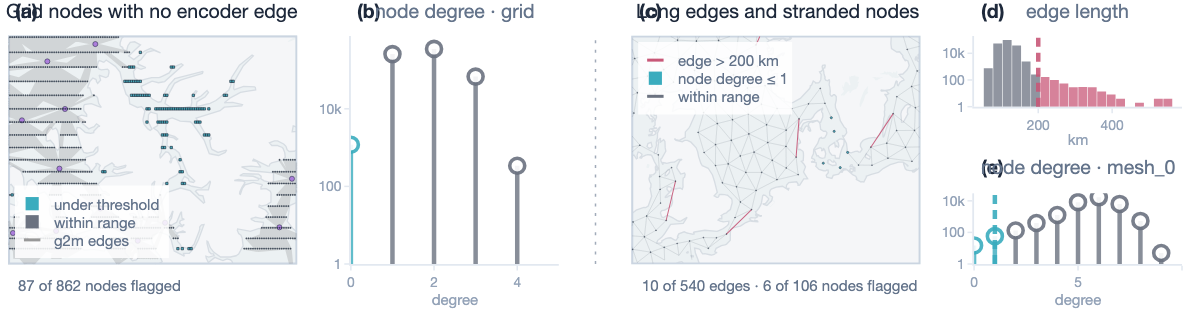

wrote /workspace/gnn-view/notebooks/figure2_ocean_defects_canadian_arctic_north_sea_baltic.pdf
wrote /workspace/gnn-view/notebooks/figure2_ocean_defects_canadian_arctic_north_sea_baltic.png
  5.5 x 1.540 in


[PosixPath('/workspace/gnn-view/notebooks/figure2_ocean_defects_canadian_arctic_north_sea_baltic.pdf'),
 PosixPath('/workspace/gnn-view/notebooks/figure2_ocean_defects_canadian_arctic_north_sea_baltic.png')]

In [13]:
# ── the Baltic: long edges over Denmark AND the nodes they strand ───────────
# On m2m_0 in this crop: 8 undirected edges >= 200 km, and 7 mesh nodes of degree
# <= 1 (3 of them 0). Five of those sit in the Danish straits — the Baltic coming
# loose from the North Sea, which is exactly what the long hops are doing.
#
# hi=200 on the edges: m2m_0 tops out at 265 km here, so 200 catches the hops
#   without sweeping in the ordinary 100-150 km mesh spacing.
# node_lo=1: flags degree 0 AND degree 1. lo=0 alone would show only the three
#   fully-detached nodes and miss the ones hanging by a single edge.

reg1="canadian_arctic"
reg2="north_sea_baltic"

V_BALTIC = [

    dict(graph="prod_cluster_noconnect", subgraph=GRID_BLOCK, metric="grid_deg",
         lo=0, hi=None, region=reg1, zoom=2.0,
         show_subgraph=False,
         legend_loc="bottom-left",
         title=f2.GRID_BLOCK_TITLE[GRID_BLOCK]),

    dict(graph="prod_cluster_default", subgraph="m2m_0",
         metric="length",     lo=None,     hi=200.0,      # edges: the hops
         node_metric="mesh_deg", node_lo=1, node_hi=None,  # nodes: what they strand
         region=reg2, zoom=1.3,
         legend_loc="top-left",
         legend_labels={"hi": "edge > 200 km", "node_lo": "node degree ≤ 1",
                        "neutral": "within range"},
         title="Long edges and stranded nodes")
]    

# The dual block's column is split: edge length on top, node degree underneath, in
# the order the caption reports them. DIST_SPLIT_GAP sets the space between the two
# — it has to carry the top chart's tick labels, its "km" title, and the lower
# chart's title, so below ~0.34 they overlap. DIST_SPLIT=False falls back to one
# chart (the edge metric only), which is the right-hand block below.
fig = f2.with_blocks(V_BALTIC, DIST_SPLIT_GAP=0.38)
fig.show()


f2.export(fig, f"figure2_ocean_defects_{reg1}_{reg2}", formats=("pdf", "png"), dpi=400)


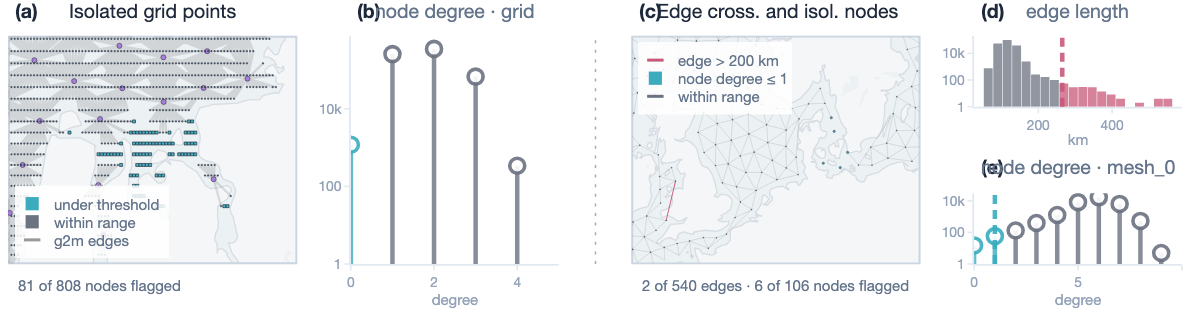

In [23]:
# ── the Baltic: long edges over Denmark AND the nodes they strand ───────────
# On m2m_0 in this crop: 8 undirected edges >= 200 km, and 7 mesh nodes of degree
# <= 1 (3 of them 0). Five of those sit in the Danish straits — the Baltic coming
# loose from the North Sea, which is exactly what the long hops are doing.
#
# hi=200 on the edges: m2m_0 tops out at 265 km here, so 200 catches the hops
#   without sweeping in the ordinary 100-150 km mesh spacing.
# node_lo=1: flags degree 0 AND degree 1. lo=0 alone would show only the three
#   fully-detached nodes and miss the ones hanging by a single edge.
#
# shift=(dx, dy) moves a crop without resizing it: +dx right, -dx left, +dy up,
#   -dy down, measured in the crop's OWN width and height, so (0.5, 0) is half a
#   panel to the right and the same nudge means the same thing at any zoom=.

reg1="kara_ob"
reg2="north_sea_baltic"

V_BALTIC = [

    dict(graph="prod_cluster_noconnect", subgraph=GRID_BLOCK, metric="grid_deg",
         lo=0, hi=None, region=reg1, zoom=2.5, shift=(0.0, 0.0),
         show_subgraph=False,
         legend_loc="bottom-left",
         title="Isolated grid points"),

    dict(graph="prod_cluster_default", subgraph="m2m_0",
         metric="length",     lo=None,     hi=265.0,      # edges: the hops
         node_metric="mesh_deg", node_lo=1, node_hi=None,  # nodes: what they strand
         region=reg2, zoom=1.3, shift=(0.0, 0.0),
         legend_loc="top-left",
         legend_labels={"hi": "edge > 200 km", "node_lo": "node degree ≤ 1",
                        "neutral": "within range"},
         title="Edge cross. and isol. nodes")
]    

# The dual block's column is split: edge length on top, node degree underneath, in
# the order the caption reports them. DIST_SPLIT_GAP sets the space between the two
# — it has to carry the top chart's tick labels, its "km" title, and the lower
# chart's title, so below ~0.34 they overlap. DIST_SPLIT=False falls back to one
# chart (the edge metric only), which is the right-hand block below.
fig = f2.with_blocks(V_BALTIC, DIST_SPLIT_GAP=0.38)
fig.show()


# f2.export(fig, f"figure2_ocean_defects_{reg1}_{reg2}", formats=("pdf", "png"), dpi=400)


## 7 · Variants

Alternate pairs of blocks. `f2.with_blocks` is `f2.build` with saving attached:
pass `stem="name"` to write it (PDF + PNG by default; `formats=` and `dpi=` to
choose), and any setting as a keyword.

Settings passed to `with_blocks` apply to the whole figure. To make the two panels
differ, put the setting in the block's own `settings={...}` — it scopes to that
block's marks, charts, key and crop. Layout settings (`FIG_W_IN`, `MAP_W`, `GAP_*`,
`MARGIN_IN`, `DIVIDER`) are read once for the figure and are rejected there.


In [ ]:
# The production graph as built -- no sabotage. Its land-crossing edges are real.
V_AS_BUILT = [
    dict(graph="prod_cluster_default", subgraph="m2m_0", metric="length",
         lo=None, hi=250.0, region="indonesia", title="Mesh edges crossing land"),
    dict(graph="prod_cluster_noconnect", subgraph="g2m", metric="grid_deg",
         lo=1, hi=None, region="canadian_arctic", zoom=2.0,
         title="Grid nodes with only one encoder edge"),
]

# Isolated MESH nodes instead of grid nodes on the right.
V_MESH_ISO = [
    dict(graph="prod_cluster_default", subgraph="m2m_0", metric="length",
         lo=None, hi=250.0, region="philippines", title="Mesh edges crossing land"),
    dict(graph="prod_cluster_default", subgraph="m2m_0", metric="mesh_deg",
         lo=1, hi=None, region="baltic_mesh", title="Mesh nodes with no neighbour"),
]

# The encoder blind spot beside the decoder one: same graph, same crop, the two
# sides of the grid<->mesh coupling. This is the pair GRID_BLOCK switches between.
V_ENC_VS_DEC = [
    dict(graph="prod_cluster_noconnect", subgraph="g2m", metric="grid_deg",
         lo=0, hi=None, region="canadian_arctic", zoom=2.0, title="No encoder edge (g2m)"),
    dict(graph="prod_cluster_noconnect", subgraph="m2g", metric="grid_deg",
         lo=0, hi=None, region="canadian_arctic", zoom=2.0, title="No decoder edge (m2g)"),
]

# The length-cutoff counterfactual: default vs a cutoff below the mesh spacing.
V_CUTOFF = [
    dict(graph="prod_cluster_default", subgraph="m2m_0", metric="length",
         lo=None, hi=250.0, region="north_atlantic", title="max_chord_len = 0.10 (default)"),
    dict(graph="prod_cluster_lowcut", subgraph="m2m_0", metric="mesh_deg",
         lo=1, hi=None, region="north_atlantic", title="max_chord_len = 0.016"),
]

# The subgraph itself, not just the nodes. zoom=3 drops the crop to ~300 g2m edges,
# which is under SUBGRAPH_ARROW_MAX_E, so the arrowheads showing grid -> mesh appear.
V_FULL_SUBGRAPH = [
    dict(graph="prod_cluster_noconnect", subgraph="g2m", metric="grid_deg",
         lo=0, hi=None, region="canadian_arctic", zoom=3.0, show_subgraph=True,
         title="g2m in full — no encoder edge"),
    dict(graph="prod_cluster_noconnect", subgraph="m2g", metric="grid_deg",
         lo=0, hi=None, region="canadian_arctic", zoom=3.0, show_subgraph=True,
         title="m2g in full — no decoder edge"),
]

# The two new crops. panama is a length crop where the LEVEL's own scale decides
# the threshold — the figure's 700 km cutoff on m2m_2 flags nothing here, because
# the longest edge near the isthmus is 689 km; m2m_1 at 300 km is what bites.
# ob_yenisei is the southern Kara Sea — the Gulf of Ob and the Yenisei Gulf in one
# frame. kara_ob is the same cluster framed wider (7 more nodes, further out on
# the shelf); this is the tight version that fills the panel.
V_NEW_CROPS = [
    dict(graph="prod_cluster_default", subgraph="m2m_1", metric="length",
         lo=None, hi=300.0, region="panama", zoom=1.0, legend_loc="bottom-left",
         title="Mesh edges crossing the isthmus"),
    dict(graph="prod_cluster_noconnect", subgraph="g2m", metric="grid_deg",
         lo=0, hi=None, region="ob_yenisei", zoom=1.0, legend_loc="top-right",
         title="Grid nodes with no encoder edge"),
]

# Per-panel settings: these two crops hold very different node densities, so the
# tight one carries a bigger flagged-node boost and a heavier basemap than its
# neighbour. Anything local to a block can differ this way.
V_PER_BLOCK = [
    dict(graph="prod_cluster_noconnect", subgraph="g2m", metric="grid_deg",
         lo=0, hi=None, region="ob_yenisei", zoom=1.0, legend_loc="top-right",
         settings={"VIOL_NODE_BOOST": 2.2, "BASEMAP_ALPHA": 0.55},
         title="Kara Sea — wide, dense"),
    dict(graph="prod_cluster_noconnect", subgraph="g2m", metric="grid_deg",
         lo=0, hi=None, region="canadian_arctic", zoom=3.0, legend_loc="bottom-left",
         settings={"VIOL_NODE_BOOST": 4.5, "BASEMAP_ALPHA": 0.80},
         title="Sverdrup Basin — tight, sparse"),
]

f2.with_blocks(V_PER_BLOCK).show()

# Saving a variant: writes <stem>.pdf and <stem>.png next to the notebook.
# f2.with_blocks(V_NEW_CROPS, stem="figure2_variant_crops", dpi=400)
